In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load master dataset
master_path = '../data/processed/kansas_housing_model_master.csv'
df_master = pd.read_csv(master_path)

print(f"Master Dataset Shape: {df_master.shape}")
display(df_master.info())

# Check missing values per column
print("\nMissing Values Count:")
print(df_master.isnull().sum())

display(df_master.head(10))

Master Dataset Shape: (912, 11)
<class 'pandas.DataFrame'>
RangeIndex: 912 entries, 0 to 911
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   metro_name         912 non-null    str    
 1   msa_code           912 non-null    int64  
 2   year               912 non-null    int64  
 3   quarter            912 non-null    int64  
 4   index_value        912 non-null    float64
 5   standard_error     912 non-null    str    
 6   quarterly_growth   912 non-null    float64
 7   mortgage_rate      912 non-null    float64
 8   median_income      823 non-null    float64
 9   unemployment_rate  730 non-null    float64
 10  building_permits   298 non-null    float64
dtypes: float64(6), int64(3), str(2)
memory usage: 96.2 KB


None


Missing Values Count:
metro_name             0
msa_code               0
year                   0
quarter                0
index_value            0
standard_error         0
quarterly_growth       0
mortgage_rate          0
median_income         89
unemployment_rate    182
building_permits     614
dtype: int64


,metro_name,msa_code,year,quarter,index_value,standard_error,quarterly_growth,mortgage_rate,median_income,unemployment_rate,building_permits
0,"Kansas City, MO-KS",28140,1976,2,45.25,( 0.54),0.689809,8.776923,NaN,NaN,NaN
1,"Kansas City, MO-KS",28140,1976,3,46.30,( 0.48),2.320442,8.967692,NaN,NaN,NaN
2,"Kansas City, MO-KS",28140,1976,4,46.19,( 0.50),-0.237581,8.847143,NaN,NaN,NaN
3,"Kansas City, MO-KS",28140,1977,1,47.15,( 0.57),2.078372,8.693333,NaN,NaN,NaN
4,"Kansas City, MO-KS",28140,1977,2,49.72,( 0.45),5.450689,8.807692,NaN,NaN,NaN
5,"Kansas City, MO-KS",28140,1977,3,51.61,( 0.40),3.801287,8.925000,NaN,NaN,NaN
6,"Kansas City, MO-KS",28140,1977,4,53.88,( 0.49),4.398372,8.936923,NaN,NaN,NaN
7,"Kansas City, MO-KS",28140,1978,1,55.66,( 0.55),3.303638,9.126923,NaN,NaN,NaN
8,"Kansas City, MO-KS",28140,1978,2,58.04,( 0.48),4.275961,9.557692,NaN,NaN,NaN
9,"Kansas City, MO-KS",28140,1978,3,59.78,( 0.48),2.997932,9.760000,NaN,NaN,NaN


### 1. Load and Inspect Master Modeling Dataset
- Loads the merged master dataset, checks data types, inspects column names, and checks for any missing values across our target and economic indicator columns.

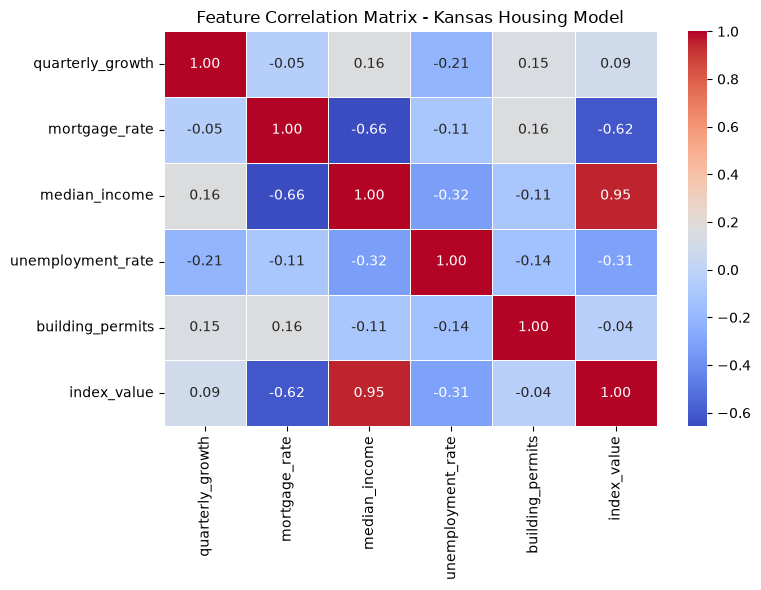

In [2]:
# Select numeric features for correlation
corr_cols = ['quarterly_growth', 'mortgage_rate', 'median_income', 'unemployment_rate', 'building_permits', 'index_value']
corr_matrix = df_master[corr_cols].corr()

# Plot correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Matrix - Kansas Housing Model")
plt.tight_layout()
plt.show()

### 2. Correlation Matrix and Heatmap
- Calculates the Pearson correlation coefficients between our target variable (`quarterly_growth`) and our independent predictors (`mortgage_rate`, `median_income`, `unemployment_rate`, `building_permits`), visualizing relationships via a Seaborn heatmap.

In [3]:
# Sort properly before creating lags
df_master = df_master.sort_values(by=['metro_name', 'year', 'quarter']).reset_index(drop=True)

# Create 1-quarter and 4-quarter lags for key predictors
features_to_lag = ['mortgage_rate', 'unemployment_rate', 'building_permits']

for feat in features_to_lag:
    df_master[f'{feat}_lag1'] = df_master.groupby('metro_name')[feat].shift(1)
    df_master[f'{feat}_lag4'] = df_master.groupby('metro_name')[feat].shift(4)

# Drop initial rows where lags resulted in NaNs
df_featured = df_master.dropna().copy()

print(f"Dataset shape after engineering lags: {df_featured.shape}")
display(df_featured[['metro_name', 'year', 'quarter', 'quarterly_growth', 'mortgage_rate', 'mortgage_rate_lag1']].head(10))

Dataset shape after engineering lags: (140, 17)


,metro_name,year,quarter,quarterly_growth,mortgage_rate,mortgage_rate_lag1
59,"Kansas City, MO-KS",1991,1,1.037510,9.500769,9.959231
60,"Kansas City, MO-KS",1991,2,0.586775,9.522308,9.500769
61,"Kansas City, MO-KS",1991,3,0.067310,9.273077,9.522308
62,"Kansas City, MO-KS",1991,4,1.356502,8.690000,9.273077
63,"Kansas City, MO-KS",1992,1,0.353943,8.688462,8.690000
64,"Kansas City, MO-KS",1992,2,0.121239,8.677692,8.688462
65,"Kansas City, MO-KS",1992,3,0.957728,8.017692,8.677692
66,"Kansas City, MO-KS",1992,4,0.457965,8.192143,8.017692
67,"Kansas City, MO-KS",1993,1,0.293064,7.723333,8.192143
68,"Kansas City, MO-KS",1993,2,0.508658,7.453077,7.723333


### 3. Engineering Lag Features for Real Estate Dynamics
- Because economic changes impact housing markets with a time delay, this block generates 1-quarter and 4-quarter lag features for mortgage rates, unemployment, and building permits grouped by metropolitan area.

In [4]:
# Save feature-engineered dataset
output_path = '../data/processed/kansas_housing_features_master.csv'
df_featured.to_csv(output_path, index=False)

print(f"Feature-engineered modeling dataset successfully saved to {output_path}!")

Feature-engineered modeling dataset successfully saved to ../data/processed/kansas_housing_features_master.csv!


### 4. Exporting Feature-Engineered Dataset
- Saves the finalized dataset containing lag features as `kansas_housing_features_master.csv`, ready for the model training and diagnostics phase.